In [1]:

# ============================================================
#  PREPARAÇÃO DOS DADOS - MCA PENSE 2024
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings

from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# Arquivo de entrada
arquivo = (
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024/"
    "08_PENSE2024_MCA_COORDENADAS.feather"
)

# Carregar dados
df_mca = pd.read_feather(arquivo)

print("=" * 65)
print("BASE DE COORDENADAS MCA - PENSE 2024")
print("=" * 65)

print(f"\nDimensões da base: {df_mca.shape}")
print(f"Quantidade de registros: {len(df_mca):,}")
print(f"Quantidade de colunas: {len(df_mca.columns)}")

# Identificar automaticamente colunas de coordenadas MCA
padrao_mca = re.compile(
    r"(dim|dimension|coord|axis|eixo|factor|component)",
    re.IGNORECASE
)

colunas_numericas = df_mca.select_dtypes(
    include=[np.number]
).columns.tolist()

colunas_mca = [
    c for c in colunas_numericas
    if padrao_mca.search(str(c))
]

# Caso os nomes não identifiquem as dimensões,
# utilizar todas as colunas numéricas, exceto identificadores.
if len(colunas_mca) < 2:

    colunas_mca = [
        c for c in colunas_numericas
        if not re.search(
            r"(^id$|^id_|_id$|codigo|código|identificador)",
            str(c),
            re.IGNORECASE
        )
    ]

print("\nColunas utilizadas na análise MCA:")
print(colunas_mca)

if len(colunas_mca) < 2:
    raise ValueError(
        "Não foram encontradas pelo menos duas colunas numéricas "
        "para realizar a clusterização."
    )

# Criar matriz de coordenadas
X = df_mca[colunas_mca].copy()

# Substituir valores infinitos por NaN
X = X.replace([np.inf, -np.inf], np.nan)

# Remover registros com coordenadas ausentes
mascara_validos = X.notna().all(axis=1)

X = X.loc[mascara_validos].copy()

# Preservar índice dos registros originais
indices_validos = X.index

print("\nResultado da preparação:")
print(f"Registros válidos: {len(X):,}")
print(f"Registros removidos: {len(df_mca) - len(X):,}")
print(f"Dimensões MCA utilizadas: {X.shape[1]}")

# Converter para matriz NumPy
X_array = X.to_numpy(dtype=float)

# Identificar as duas primeiras dimensões para gráficos
dim1 = colunas_mca[0]
dim2 = colunas_mca[1]

print(f"\nGráficos utilizarão: {dim1} x {dim2}")


BASE DE COORDENADAS MCA - PENSE 2024

Dimensões da base: (118036, 31)
Quantidade de registros: 118,036
Quantidade de colunas: 31

Colunas utilizadas na análise MCA:
['indice_original', 'MCA_1', 'MCA_2', 'MCA_3', 'MCA_4', 'MCA_5', 'MCA_6', 'MCA_7', 'MCA_8', 'MCA_9', 'MCA_10', 'MCA_11', 'MCA_12', 'MCA_13', 'MCA_14', 'MCA_15', 'MCA_16', 'MCA_17', 'MCA_18', 'MCA_19', 'MCA_20', 'MCA_21', 'MCA_22', 'MCA_23', 'MCA_24', 'MCA_25', 'MCA_26', 'MCA_27', 'MCA_28', 'MCA_29', 'MCA_30']

Resultado da preparação:
Registros válidos: 118,036
Registros removidos: 0
Dimensões MCA utilizadas: 31

Gráficos utilizarão: indice_original x MCA_1


Executando GMM...

K=2 | BIC=-921790.54 | AIC=-923000.38
K=3 | BIC=-1257945.63 | AIC=-1259765.23
K=4 | BIC=-1516266.87 | AIC=-1518696.24
K=5 | BIC=-1621770.41 | AIC=-1624809.54
K=6 | BIC=-1853718.94 | AIC=-1857367.83
K=7 | BIC=-1914971.21 | AIC=-1919229.86
K=8 | BIC=-2039045.41 | AIC=-2043913.82
K=9 | BIC=-1988165.51 | AIC=-1993643.67
K=10 | BIC=-2159136.65 | AIC=-2165224.58

RESULTADOS GMM

Melhor número de clusters pelo BIC: 10
Silhouette Score: -0.0978

Distribuição dos clusters:
Cluster_GMM
0     2576
1    18197
2    21830
3    16114
4     1495
5    14828
6     3539
7    15483
8     2136
9    21838
Name: count, dtype: int64

Confiança média de classificação por cluster:
Cluster_GMM
0    0.9854
1    0.9455
2    0.9661
3    0.9874
4    0.9686
5    0.9547
6    0.9826
7    0.9325
8    0.9934
9    0.9370
Name: Confianca_GMM, dtype: float64

Comparação BIC e AIC:


,Clusters,BIC,AIC,Convergiu,Iteracoes
0,2,-921790.54,-923000.38,True,9
1,3,-1257945.63,-1259765.23,True,21
2,4,-1516266.87,-1518696.24,True,31
3,5,-1621770.41,-1624809.54,True,29
4,6,-1853718.94,-1857367.83,True,36
5,7,-1914971.21,-1919229.86,True,43
6,8,-2039045.41,-2043913.82,True,53
7,9,-1988165.51,-1993643.67,True,29
8,10,-2159136.65,-2165224.58,True,33


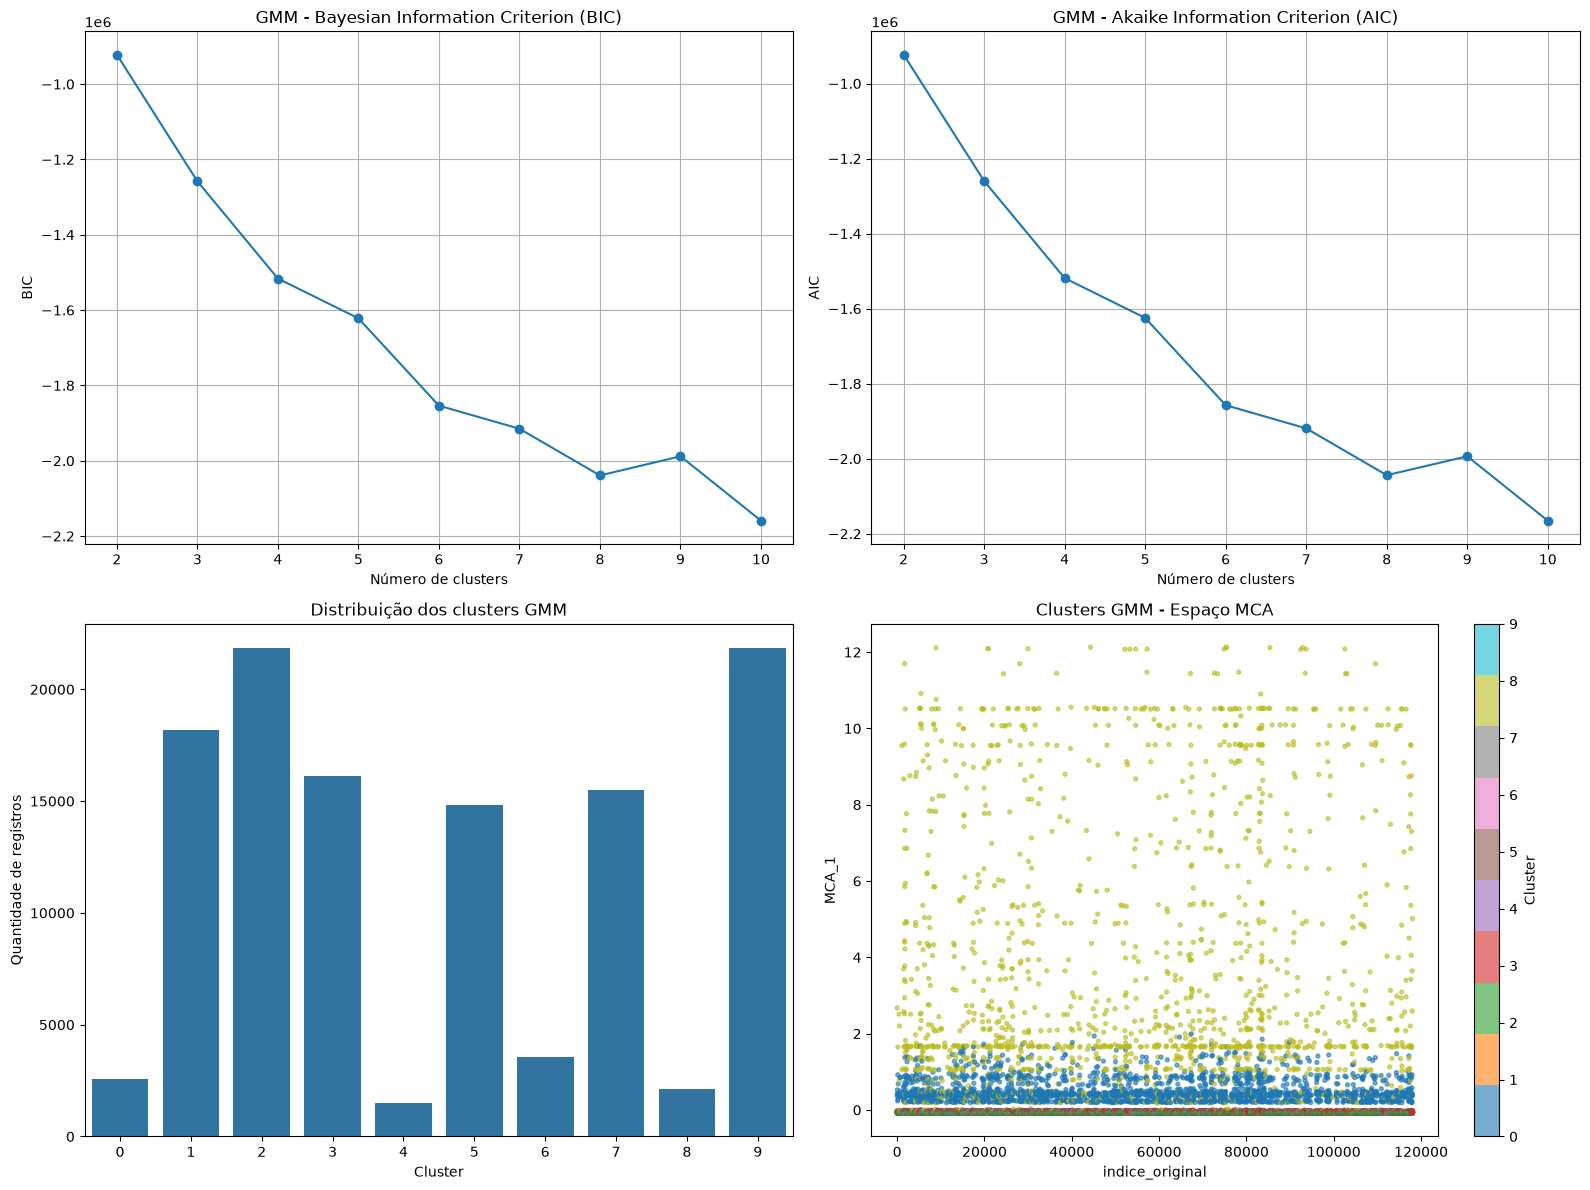


Probabilidade média de pertencimento:
Cluster 0: 0.0218
Cluster 1: 0.1537
Cluster 2: 0.1845
Cluster 3: 0.1362
Cluster 4: 0.0130
Cluster 5: 0.1264
Cluster 6: 0.0299
Cluster 7: 0.1304
Cluster 8: 0.0182
Cluster 9: 0.1858

Registros com classificação de baixa confiança (< 0.60):
3312


In [2]:

# ============================================================
#  GMM - GAUSSIAN MIXTURE MODELS
#  PENSE 2024 - COORDENADAS MCA
# ============================================================

from sklearn.mixture import GaussianMixture

# Parâmetros
K_MIN = 2
K_MAX = 10

# Avaliação de diferentes quantidades de clusters
resultados_gmm = []

modelos_gmm = {}

print("Executando GMM...\n")

for k in range(K_MIN, K_MAX + 1):

    modelo = GaussianMixture(
        n_components=k,
        covariance_type="diag",
        random_state=42,
        n_init=3,
        max_iter=300,
        reg_covar=1e-6
    )

    modelo.fit(X_array)

    bic = modelo.bic(X_array)
    aic = modelo.aic(X_array)

    modelos_gmm[k] = modelo

    resultados_gmm.append({
        "Clusters": k,
        "BIC": bic,
        "AIC": aic,
        "Convergiu": modelo.converged_,
        "Iteracoes": modelo.n_iter_
    })

    print(f"K={k} | BIC={bic:.2f} | AIC={aic:.2f}")

# Tabela comparativa
df_gmm = pd.DataFrame(resultados_gmm)

# Selecionar modelo pelo menor BIC
melhor_k_gmm = int(
    df_gmm.loc[df_gmm["BIC"].idxmin(), "Clusters"]
)

modelo_gmm = modelos_gmm[melhor_k_gmm]

# Classificação final
clusters_gmm = modelo_gmm.predict(X_array)

# Probabilidades de pertencimento
probabilidades_gmm = modelo_gmm.predict_proba(X_array)

# Confiança da classificação: maior probabilidade
confianca_gmm = probabilidades_gmm.max(axis=1)

# Criar resultados
df_resultado_gmm = df_mca.loc[indices_validos].copy()

df_resultado_gmm["Cluster_GMM"] = clusters_gmm
df_resultado_gmm["Confianca_GMM"] = confianca_gmm

# Silhouette Score (amostra para reduzir custo computacional)
if len(X) > 10000:
    rng = np.random.RandomState(42)
    amostra = rng.choice(len(X), 10000, replace=False)
else:
    amostra = np.arange(len(X))

labels_amostra = clusters_gmm[amostra]

if len(np.unique(labels_amostra)) > 1:
    silhouette_gmm = silhouette_score(
        X_array[amostra],
        labels_amostra
    )
else:
    silhouette_gmm = np.nan

# ============================================================
# RESULTADOS
# ============================================================

print("\n" + "=" * 65)
print("RESULTADOS GMM")
print("=" * 65)

print(f"\nMelhor número de clusters pelo BIC: {melhor_k_gmm}")
print(f"Silhouette Score: {silhouette_gmm:.4f}")

print("\nDistribuição dos clusters:")

print(
    df_resultado_gmm["Cluster_GMM"]
    .value_counts()
    .sort_index()
)

print("\nConfiança média de classificação por cluster:")

print(
    df_resultado_gmm.groupby("Cluster_GMM")["Confianca_GMM"]
    .mean()
    .round(4)
)

print("\nComparação BIC e AIC:")

display(df_gmm.round(2))

# ============================================================
# GRÁFICOS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1 - BIC
axes[0, 0].plot(
    df_gmm["Clusters"],
    df_gmm["BIC"],
    marker="o"
)

axes[0, 0].set_title("GMM - Bayesian Information Criterion (BIC)")
axes[0, 0].set_xlabel("Número de clusters")
axes[0, 0].set_ylabel("BIC")
axes[0, 0].grid(True)

# 2 - AIC
axes[0, 1].plot(
    df_gmm["Clusters"],
    df_gmm["AIC"],
    marker="o"
)

axes[0, 1].set_title("GMM - Akaike Information Criterion (AIC)")
axes[0, 1].set_xlabel("Número de clusters")
axes[0, 1].set_ylabel("AIC")
axes[0, 1].grid(True)

# 3 - Distribuição dos clusters
sns.countplot(
    x="Cluster_GMM",
    data=df_resultado_gmm,
    ax=axes[1, 0]
)

axes[1, 0].set_title("Distribuição dos clusters GMM")
axes[1, 0].set_xlabel("Cluster")
axes[1, 0].set_ylabel("Quantidade de registros")

# 4 - Visualização MCA
scatter = axes[1, 1].scatter(
    X[dim1],
    X[dim2],
    c=clusters_gmm,
    cmap="tab10",
    s=8,
    alpha=0.6
)

axes[1, 1].set_title("Clusters GMM - Espaço MCA")
axes[1, 1].set_xlabel(dim1)
axes[1, 1].set_ylabel(dim2)

plt.colorbar(scatter, ax=axes[1, 1], label="Cluster")

plt.tight_layout()
plt.show()

# ============================================================
# ANÁLISE ADICIONAL
# ============================================================

print("\nProbabilidade média de pertencimento:")

for k in range(melhor_k_gmm):
    print(
        f"Cluster {k}: "
        f"{probabilidades_gmm[:, k].mean():.4f}"
    )

print("\nRegistros com classificação de baixa confiança (< 0.60):")

print(
    (confianca_gmm < 0.60).sum()
)



AVALIAÇÃO AMPLIADA DO GMM - PENSE 2024

MÉTRICAS GERAIS


,Metrica,Resultado
0,BIC,-2.159137e+06
1,AIC,-2.165225e+06
2,Log-Likelihood médio,9.177200e+00
3,Log-Likelihood total,1.083241e+06
4,Silhouette Score,-9.780000e-02
5,Calinski-Harabasz,2.100530e+01
6,Davies-Bouldin,7.980270e+01
7,Entropia média,1.078000e-01
8,Entropia normalizada,4.680000e-02
9,Classification Uncertainty,4.390000e-02



SILHOUETTE POR CLUSTER


,Media,Mediana,Desvio_Padrao,Minimo,Maximo,Observacoes
Cluster,,,,,,
0,-0.0910,-0.1125,0.0574,-0.1728,0.0333,225
1,-0.1163,-0.1316,0.0357,-0.1569,-0.0421,1532
2,-0.1093,-0.0785,0.0598,-0.2119,-0.0233,1827
3,-0.0762,-0.0201,0.1165,-0.2541,0.0460,1384
4,-0.1199,-0.0785,0.1052,-0.2697,0.0161,132
5,-0.0260,0.0497,0.1307,-0.2427,0.1021,1277
6,-0.1310,-0.1303,0.0405,-0.1982,-0.0645,297
7,-0.1075,-0.0464,0.0897,-0.2525,-0.0167,1339
8,-0.1340,-0.1243,0.0495,-0.2110,-0.0559,171



CLASSIFICAÇÃO POR NÍVEL DE CONFIANÇA


,Classificacao,Quantidade,Percentual
0,Alta confiança (>= 0.80),107590,91.15
1,Média confiança (0.60 a 0.79),7134,6.04
2,Baixa confiança (< 0.60),3312,2.81


... (2 outputs left out)


MASSA PROBABILÍSTICA DOS COMPONENTES


,Cluster,Percentual_Classificacao,Massa_Probabilistica_Percentual
0,0,2.18,2.18
1,1,15.42,15.37
2,2,18.49,18.45
3,3,13.65,13.62
4,4,1.27,1.30
5,5,12.56,12.64
6,6,3.00,2.99
7,7,13.12,13.04
8,8,1.81,1.82
9,9,18.50,18.58



DISTÂNCIA ENTRE AS MÉDIAS DOS COMPONENTES


,Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Cluster 6,Cluster 7,Cluster 8,Cluster 9
Cluster 0,0.0000,2189.3025,6095.3002,9604.3323,6079.2970,3833.1784,892.0386,7840.6289,3695.0668,63.6560
Cluster 1,2189.3025,0.0000,3905.9977,7415.0298,3889.9947,6022.4808,1297.2647,5651.3265,5884.3692,2125.6499
Cluster 2,6095.3002,3905.9977,0.0000,3509.0322,16.0710,9928.4785,5203.2622,1745.3288,9790.3666,6031.6475
Cluster 3,9604.3323,7415.0298,3509.0322,0.0000,3525.0357,13437.5106,8712.2942,1763.7035,13299.3985,9540.6796
Cluster 4,6079.2970,3889.9947,16.0710,3525.0357,0.0000,9912.4753,5187.2590,1761.3327,9774.3633,6015.6444
Cluster 5,3833.1784,6022.4808,9928.4785,13437.5106,9912.4753,0.0000,4725.2165,11673.8073,138.1445,3896.8310
Cluster 6,892.0386,1297.2647,5203.2622,8712.2942,5187.2590,4725.2165,0.0000,6948.5909,4587.1050,828.3858
Cluster 7,7840.6289,5651.3265,1745.3288,1763.7035,1761.3327,11673.8073,6948.5909,0.0000,11535.6953,7776.9763
Cluster 8,3695.0668,5884.3692,9790.3666,13299.3985,9774.3633,138.1445,4587.1050,11535.6953,0.0000,3758.7198
Cluster 9,63.6560,2125.6499,6031.6475,9540.6796,6015.6444,3896.8310,828.3858,7776.9763,3758.7198,0.0000


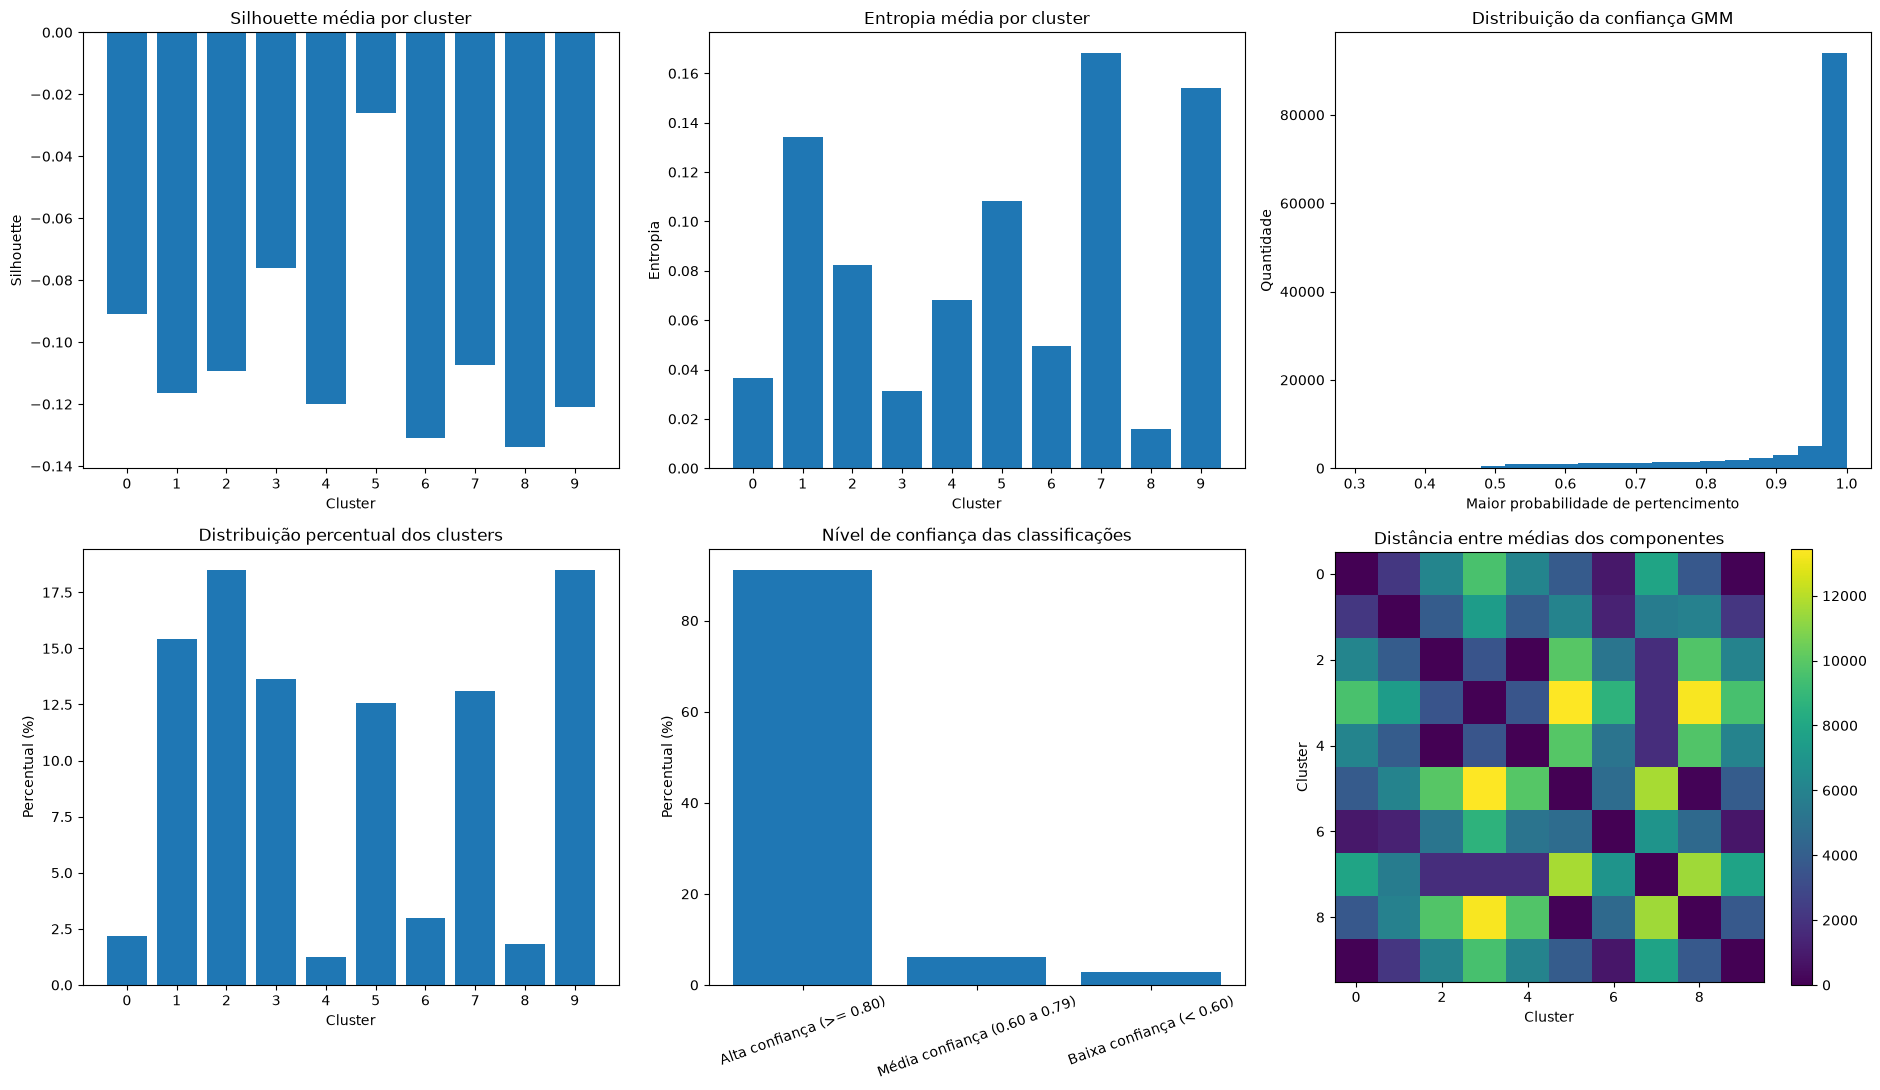


Avaliação ampliada do GMM concluída.


In [3]:

# ============================================================
# 9. MÉTRICAS ADICIONAIS DE AVALIAÇÃO DO GMM
# PENSE 2024 - COORDENADAS MCA
# ============================================================

from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_samples,
    silhouette_score,
    adjusted_rand_score,
    pairwise_distances
)

from sklearn.mixture import GaussianMixture

# ------------------------------------------------------------
# 9.1. PREPARAÇÃO DA AMOSTRA
# ------------------------------------------------------------

# Amostra fixa para métricas que utilizam distâncias
MAX_AMOSTRA = 10000

if len(X_array) > MAX_AMOSTRA:

    rng = np.random.RandomState(42)

    indices_amostra_gmm = rng.choice(
        len(X_array),
        MAX_AMOSTRA,
        replace=False
    )

else:

    indices_amostra_gmm = np.arange(len(X_array))

X_avaliacao = X_array[indices_amostra_gmm]

clusters_avaliacao = clusters_gmm[indices_amostra_gmm]

probabilidades_avaliacao = probabilidades_gmm[
    indices_amostra_gmm
]

# ------------------------------------------------------------
# 9.2. CALINSKI-HARABASZ INDEX
# ------------------------------------------------------------

ch_score_gmm = calinski_harabasz_score(
    X_avaliacao,
    clusters_avaliacao
)

# ------------------------------------------------------------
# 9.3. DAVIES-BOULDIN INDEX
# ------------------------------------------------------------

db_score_gmm = davies_bouldin_score(
    X_avaliacao,
    clusters_avaliacao
)

# ------------------------------------------------------------
# 9.4. SILHOUETTE POR CLUSTER
# ------------------------------------------------------------

silhouette_individual_gmm = silhouette_samples(
    X_avaliacao,
    clusters_avaliacao
)

df_silhouette_gmm = pd.DataFrame({
    "Cluster": clusters_avaliacao,
    "Silhouette": silhouette_individual_gmm
})

silhouette_clusters_gmm = (
    df_silhouette_gmm
    .groupby("Cluster")["Silhouette"]
    .agg(["mean", "median", "std", "min", "max", "count"])
    .round(4)
)

silhouette_clusters_gmm.columns = [
    "Media",
    "Mediana",
    "Desvio_Padrao",
    "Minimo",
    "Maximo",
    "Observacoes"
]

# ------------------------------------------------------------
# 9.5. ENTROPIA DAS PROBABILIDADES
# ------------------------------------------------------------

# Entropia individual:
# Quanto maior, maior a incerteza sobre o cluster.

epsilon = 1e-12

entropia_individual = -np.sum(
    probabilidades_gmm *
    np.log(probabilidades_gmm + epsilon),
    axis=1
)

# Entropia máxima possível = log(K)
entropia_maxima = np.log(melhor_k_gmm)

# Entropia normalizada entre 0 e 1
entropia_normalizada_individual = (
    entropia_individual / entropia_maxima
)

# Média geral
entropia_media_gmm = entropia_individual.mean()

entropia_normalizada_media_gmm = (
    entropia_normalizada_individual.mean()
)

# ------------------------------------------------------------
# 9.6. CLASSIFICATION UNCERTAINTY
# ------------------------------------------------------------

# Incerteza = 1 - maior probabilidade de pertencimento

incerteza_gmm = 1 - confianca_gmm

incerteza_media_gmm = incerteza_gmm.mean()

# Classificação de alta, média e baixa confiança

alta_confianca = np.sum(confianca_gmm >= 0.80)

media_confianca = np.sum(
    (confianca_gmm >= 0.60) &
    (confianca_gmm < 0.80)
)

baixa_confianca = np.sum(confianca_gmm < 0.60)

df_confianca_gmm = pd.DataFrame({
    "Classificacao": [
        "Alta confiança (>= 0.80)",
        "Média confiança (0.60 a 0.79)",
        "Baixa confiança (< 0.60)"
    ],
    "Quantidade": [
        alta_confianca,
        media_confianca,
        baixa_confianca
    ],
    "Percentual": [
        alta_confianca / len(X_array) * 100,
        media_confianca / len(X_array) * 100,
        baixa_confianca / len(X_array) * 100
    ]
})

# ------------------------------------------------------------
# 9.7. LOG-LIKELIHOOD
# ------------------------------------------------------------

# Score médio de log-likelihood por observação
log_likelihood_medio = modelo_gmm.score(X_array)

# Log-likelihood total
log_likelihood_total = (
    modelo_gmm.score(X_array) * len(X_array)
)

# ------------------------------------------------------------
# 9.8. DISTRIBUIÇÃO E EQUILÍBRIO DOS CLUSTERS
# ------------------------------------------------------------

tamanhos_gmm = np.bincount(
    clusters_gmm,
    minlength=melhor_k_gmm
)

percentuais_gmm = (
    tamanhos_gmm / len(clusters_gmm)
) * 100

df_balance_gmm = pd.DataFrame({
    "Cluster": range(melhor_k_gmm),
    "Quantidade": tamanhos_gmm,
    "Percentual": percentuais_gmm
})

# Entropia do tamanho dos clusters
proporcoes_gmm = tamanhos_gmm / tamanhos_gmm.sum()

entropia_balance_gmm = -np.sum(
    proporcoes_gmm[proporcoes_gmm > 0] *
    np.log(proporcoes_gmm[proporcoes_gmm > 0])
)

entropia_balance_normalizada = (
    entropia_balance_gmm / np.log(melhor_k_gmm)
    if melhor_k_gmm > 1 else np.nan
)

# Proporção probabilística média de cada componente
massa_probabilistica_gmm = probabilidades_gmm.mean(axis=0)

df_massa_gmm = pd.DataFrame({
    "Cluster": range(melhor_k_gmm),
    "Percentual_Classificacao": percentuais_gmm,
    "Massa_Probabilistica_Percentual":
        massa_probabilistica_gmm * 100
})

# ------------------------------------------------------------
# 9.9. DISTÂNCIA ENTRE AS MÉDIAS DOS COMPONENTES
# ------------------------------------------------------------

distancias_medias_gmm = pairwise_distances(
    modelo_gmm.means_,
    metric="euclidean"
)

df_distancias_gmm = pd.DataFrame(
    distancias_medias_gmm,
    index=[f"Cluster {k}" for k in range(melhor_k_gmm)],
    columns=[f"Cluster {k}" for k in range(melhor_k_gmm)]
)

# ------------------------------------------------------------
# 9.10. RESULTADOS CONSOLIDADOS
# ------------------------------------------------------------

resultados_metricas_gmm = pd.DataFrame({

    "Metrica": [
        "BIC",
        "AIC",
        "Log-Likelihood médio",
        "Log-Likelihood total",
        "Silhouette Score",
        "Calinski-Harabasz",
        "Davies-Bouldin",
        "Entropia média",
        "Entropia normalizada",
        "Classification Uncertainty",
        "Cluster Balance (entropia)"
    ],

    "Resultado": [
        modelo_gmm.bic(X_array),
        modelo_gmm.aic(X_array),
        log_likelihood_medio,
        log_likelihood_total,
        silhouette_score(X_avaliacao, clusters_avaliacao),
        ch_score_gmm,
        db_score_gmm,
        entropia_media_gmm,
        entropia_normalizada_media_gmm,
        incerteza_media_gmm,
        entropia_balance_normalizada
    ]
})

print("\n" + "=" * 75)
print("AVALIAÇÃO AMPLIADA DO GMM - PENSE 2024")
print("=" * 75)

print("\nMÉTRICAS GERAIS")

display(resultados_metricas_gmm.round(4))

print("\nSILHOUETTE POR CLUSTER")

display(silhouette_clusters_gmm)

print("\nCLASSIFICAÇÃO POR NÍVEL DE CONFIANÇA")

display(df_confianca_gmm.round(2))

print("\nDISTRIBUIÇÃO DOS CLUSTERS")

display(df_balance_gmm.round(2))

print("\nMASSA PROBABILÍSTICA DOS COMPONENTES")

display(df_massa_gmm.round(2))

print("\nDISTÂNCIA ENTRE AS MÉDIAS DOS COMPONENTES")

display(df_distancias_gmm.round(4))

# ------------------------------------------------------------
# 9.11. GRÁFICOS DAS MÉTRICAS
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(19, 11))

# Gráfico 1 - Silhouette por cluster

axes[0, 0].bar(
    silhouette_clusters_gmm.index.astype(str),
    silhouette_clusters_gmm["Media"]
)

axes[0, 0].axhline(
    0,
    linestyle="--",
    alpha=0.5
)

axes[0, 0].set_title("Silhouette média por cluster")
axes[0, 0].set_xlabel("Cluster")
axes[0, 0].set_ylabel("Silhouette")

# Gráfico 2 - Entropia por cluster

entropia_por_cluster = pd.DataFrame({
    "Cluster": clusters_gmm,
    "Entropia": entropia_individual
})

entropia_por_cluster = (
    entropia_por_cluster.groupby("Cluster")["Entropia"]
    .mean()
)

axes[0, 1].bar(
    entropia_por_cluster.index.astype(str),
    entropia_por_cluster.values
)

axes[0, 1].set_title("Entropia média por cluster")
axes[0, 1].set_xlabel("Cluster")
axes[0, 1].set_ylabel("Entropia")

# Gráfico 3 - Confiança das classificações

axes[0, 2].hist(
    confianca_gmm,
    bins=20
)

axes[0, 2].set_title("Distribuição da confiança GMM")
axes[0, 2].set_xlabel("Maior probabilidade de pertencimento")
axes[0, 2].set_ylabel("Quantidade")

# Gráfico 4 - Distribuição dos clusters

axes[1, 0].bar(
    df_balance_gmm["Cluster"].astype(str),
    df_balance_gmm["Percentual"]
)

axes[1, 0].set_title("Distribuição percentual dos clusters")
axes[1, 0].set_xlabel("Cluster")
axes[1, 0].set_ylabel("Percentual (%)")

# Gráfico 5 - Classificação por confiança

axes[1, 1].bar(
    df_confianca_gmm["Classificacao"],
    df_confianca_gmm["Percentual"]
)

axes[1, 1].set_title("Nível de confiança das classificações")
axes[1, 1].set_ylabel("Percentual (%)")
axes[1, 1].tick_params(axis="x", rotation=20)

# Gráfico 6 - Distância entre componentes

im = axes[1, 2].imshow(
    distancias_medias_gmm,
    cmap="viridis"
)

axes[1, 2].set_title("Distância entre médias dos componentes")
axes[1, 2].set_xlabel("Cluster")
axes[1, 2].set_ylabel("Cluster")

plt.colorbar(im, ax=axes[1, 2])

plt.tight_layout()
plt.show()

print("\nAvaliação ampliada do GMM concluída.")


ESTABILIDADE DOS CLUSTERS GMM


,Repeticao,ARI,Convergiu,Iteracoes
0,1,0.9229,True,33
1,2,0.6759,True,44
2,3,0.8772,True,39
3,4,0.9022,True,37
4,5,0.4620,True,37



ARI médio: 0.7680
Desvio padrão: 0.1975


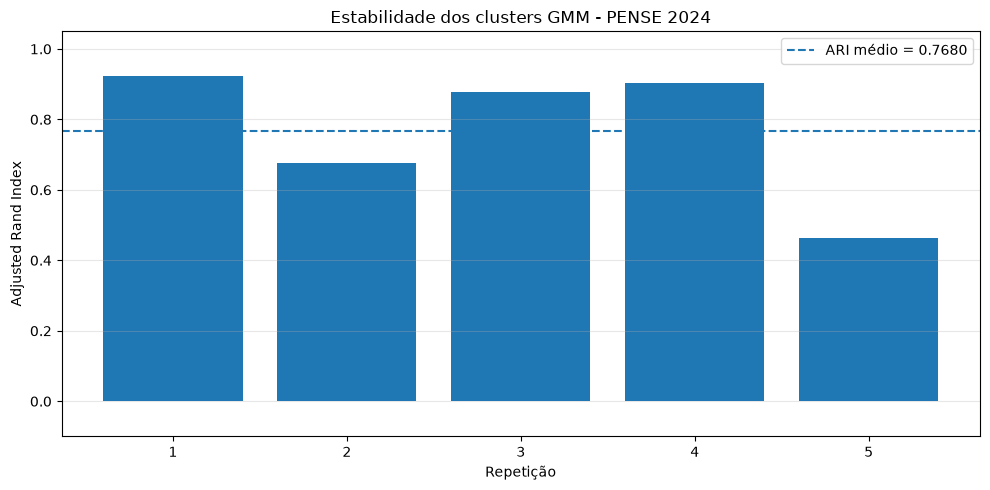


Análise de estabilidade concluída.


In [4]:

# ============================================================
# 10. ESTABILIDADE DOS CLUSTERS GMM
# ADJUSTED RAND INDEX (ARI)
# ============================================================

from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture

N_REPETICOES = 5
PERCENTUAL_AMOSTRA = 0.80
MAX_REFERENCIA = 10000

rng = np.random.default_rng(42)

# ------------------------------------------------------------
# 10.1. AMOSTRA DE REFERÊNCIA
# ------------------------------------------------------------

n_referencia = min(MAX_REFERENCIA, len(X_array))

idx_referencia = rng.choice(
    len(X_array),
    size=n_referencia,
    replace=False
)

X_referencia = X_array[idx_referencia]

# Classificação do modelo original
labels_original = modelo_gmm.predict(X_referencia)

# ------------------------------------------------------------
# 10.2. TREINAR MODELOS COM DIFERENTES AMOSTRAS
# ------------------------------------------------------------

resultados_estabilidade_gmm = []

for repeticao in range(N_REPETICOES):

    rng_rep = np.random.default_rng(100 + repeticao)

    n_treino = int(
        len(X_array) * PERCENTUAL_AMOSTRA
    )

    idx_treino = rng_rep.choice(
        len(X_array),
        size=n_treino,
        replace=False
    )

    modelo_teste = GaussianMixture(
        n_components=melhor_k_gmm,
        covariance_type=modelo_gmm.covariance_type,
        random_state=100 + repeticao,
        n_init=3,
        max_iter=300,
        reg_covar=1e-6
    )

    modelo_teste.fit(X_array[idx_treino])

    # Classificar a mesma amostra de referência
    labels_teste = modelo_teste.predict(X_referencia)

    # Comparar classificações
    ari = adjusted_rand_score(
        labels_original,
        labels_teste
    )

    resultados_estabilidade_gmm.append({
        "Repeticao": repeticao + 1,
        "ARI": ari,
        "Convergiu": modelo_teste.converged_,
        "Iteracoes": modelo_teste.n_iter_
    })

# ------------------------------------------------------------
# 10.3. RESULTADOS
# ------------------------------------------------------------

df_estabilidade_gmm = pd.DataFrame(
    resultados_estabilidade_gmm
)

print("=" * 70)
print("ESTABILIDADE DOS CLUSTERS GMM")
print("=" * 70)

display(df_estabilidade_gmm.round(4))

ari_medio_gmm = df_estabilidade_gmm["ARI"].mean()

ari_desvio_gmm = df_estabilidade_gmm["ARI"].std()

print(f"\nARI médio: {ari_medio_gmm:.4f}")
print(f"Desvio padrão: {ari_desvio_gmm:.4f}")

# ------------------------------------------------------------
# 10.4. GRÁFICO
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    df_estabilidade_gmm["Repeticao"],
    df_estabilidade_gmm["ARI"]
)

plt.axhline(
    ari_medio_gmm,
    linestyle="--",
    label=f"ARI médio = {ari_medio_gmm:.4f}"
)

plt.ylim(-0.1, 1.05)

plt.xlabel("Repetição")
plt.ylabel("Adjusted Rand Index")

plt.title("Estabilidade dos clusters GMM - PENSE 2024")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nAnálise de estabilidade concluída.")
